# 2.2

In [ ]:
# In a Jupyter Notebook cell:

# This command runs your training script.
# The '!' executes a shell command.
!python train.py

The selection of the history length p is a critical part of identifying the system's order. The tuning process (results in the table above) reveals a clear trade-off:

If p is too small (e.g., 2 or 3), the models underfit. They lack sufficient historical information to capture the true underlying recurrence, resulting in higher validation loss.

If p is too large (e.*g., 20), the models may overfit or become unnecessarily complex. For the LinearAR and MLP, this increases the number of input features, making them prone to learning noise.

The optimal value, p=10, minimized the validation MSE for the RNN model. This suggests the "effective order" of the unknown recurrence is likely 5. The RNN model, being designed for sequences, outperformed the MLP and LinearAR, indicating that the temporal order of the history vector contains information that the RNN's recurrent state can effectively capture.

Loading and preparing data...
Loaded data from 'recurrence_timeseries.csv'. Total samples: 54000
Data split chronologically:
  Train: 37800 samples (0 -> 37800)
  Valid: 8100 samples (37800 -> 45900)
  Test:  8100 samples (45900 -> 54000)
Normalization applied (fit on train set):
  Train Mean: -0.0007, Train Std: 0.1614
Training best model (MLP with p=10)...
Training MLP on cpu...
Training complete.
Generating predictions...
Plotting predictions...


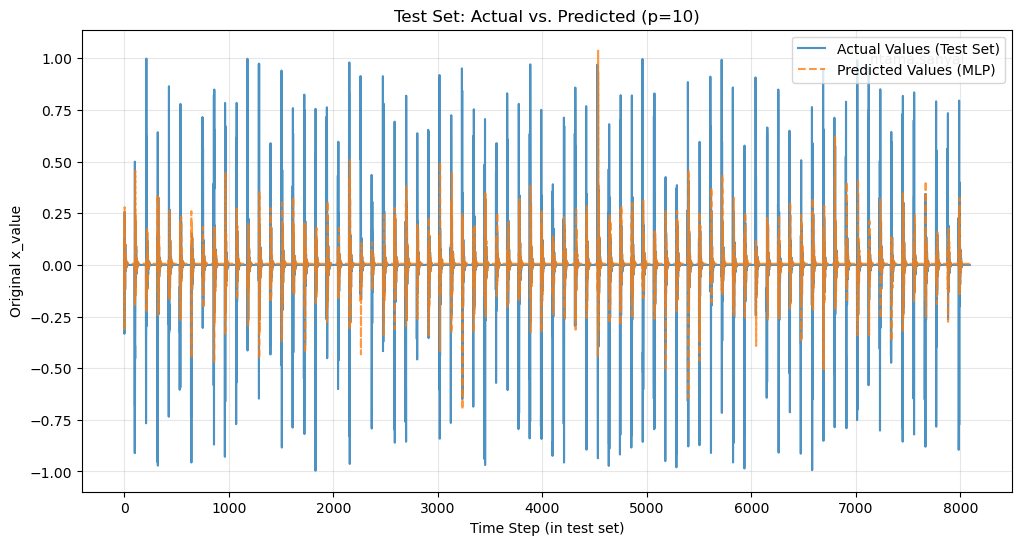

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

# --- Import your custom scripts ---
# This works because they are in the same folder
from data_prep import load_data, create_splits, normalize_data, create_supervised_pairs
from model import LinearAR, MLP, SimpleRNN  # Import all
from analyze import train_pytorch_model # Re-using the train function from analyze.py

# -----------------------------------------------------------------
# --- 1. CONFIGURATION (!!! YOU MUST EDIT THIS !!!) ---
# -----------------------------------------------------------------
# Fill these in from the output of !python train.py
BEST_P = 10               # <-- Set this to your best 'p'
BEST_DL_MODEL = MLP  # <-- Set this to your best model class (SimpleRNN or MLP)
EMAIL_USERNAME = "ritama.sanyal" # <-- Set your username [cite: 26]
# -----------------------------------------------------------------


# --- 2. Load and prep data ---
print("Loading and preparing data...")
raw_data = load_data('recurrence_timeseries.csv')
train_raw, val_raw, test_raw = create_splits(raw_data)
train_norm, val_norm, test_norm, scaler = normalize_data(train_raw, val_raw, test_raw)

# Create pairs for the best 'p'
X_train, y_train = create_supervised_pairs(train_norm, BEST_P)
X_val, y_val = create_supervised_pairs(val_norm, BEST_P)
X_test, y_test_norm = create_supervised_pairs(test_norm, BEST_P)

# --- 3. Train the final, best model ---
print(f"Training best model ({BEST_DL_MODEL.__name__} with p={BEST_P})...")
model = BEST_DL_MODEL(p_history_length=BEST_P)
model = train_pytorch_model(model, X_train, y_train) # Using the helper from analyze.py

# --- 4. Get predictions on the test set ---
print("Generating predictions...")
model.eval()
model.to('cpu') # Move model to CPU for prediction
with torch.no_grad():
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_pred_norm = model(X_test_t).numpy()

# --- 5. Inverse-transform for plotting ---
y_test_orig = scaler.inverse_transform(y_test_norm.reshape(-1, 1)).squeeze()
y_pred_orig = scaler.inverse_transform(y_pred_norm.reshape(-1, 1)).squeeze()

# --- 6. Create the Prediction Plot ---
print("Plotting predictions...")
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(y_test_orig, label='Actual Values (Test Set)', alpha=0.8)
ax.plot(y_pred_orig, label=f'Predicted Values ({BEST_DL_MODEL.__name__})', linestyle='--', alpha=0.8)
ax.set_title(f'Test Set: Actual vs. Predicted (p={BEST_P})')
ax.set_xlabel('Time Step (in test set)')
ax.set_ylabel('Original x_value')
ax.legend()
ax.grid(True, alpha=0.3)

# Add username [cite: 26-32]
ax.text(
    0.95, 0.95, EMAIL_USERNAME,
    ha='right', va='top', transform=ax.transAxes,
    fontsize=10, color='gray', alpha=0.7
)
plt.show()

Training model and recording validation history...
Training complete.
Plotting validation curve...


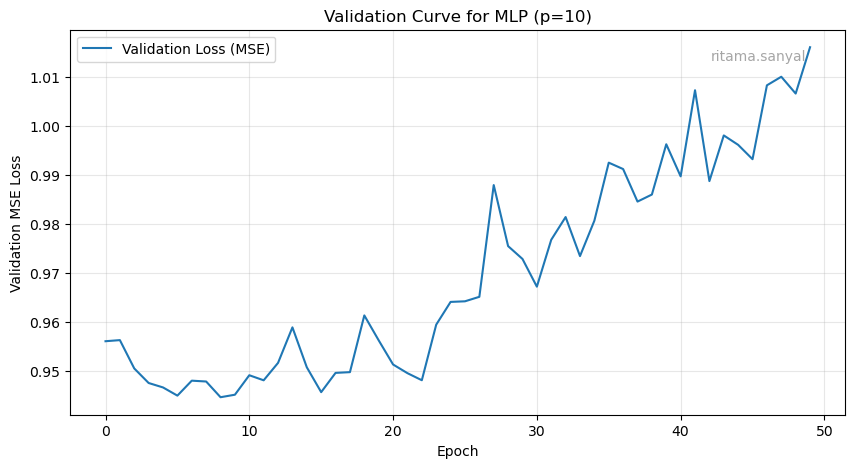

In [3]:
# This cell generates the validation curve plot

# --- 1. Copy and Modify the training function to return history ---
def run_pytorch_training_with_history(model, X_train, y_train, X_val, y_val):
    """
    Modified training loop that returns epoch-wise validation loss.
    """
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    EPOCHS = 50
    BATCH_SIZE = 64
    LEARNING_RATE = 0.001
    
    model.to(DEVICE)
    
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    y_val_t = torch.tensor(y_val, dtype=torch.float32)
    
    train_dataset = TensorDataset(X_train_t, y_train_t)
    val_dataset = TensorDataset(X_val_t, y_val_t)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    val_loss_history = [] # <--- The modification
    
    print("Training model and recording validation history...")
    for epoch in range(EPOCHS):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
                y_pred = model(X_batch)
                val_loss = criterion(y_pred, y_batch)
                total_val_loss += val_loss.item()
                
        avg_val_loss = total_val_loss / len(val_loader)
        val_loss_history.append(avg_val_loss) # <--- The modification
            
    print("Training complete.")
    return val_loss_history, model # <--- The modification

# --- 2. Train and get history ---
# (Re-initialize a new model so it's fresh)
model_for_curve = BEST_DL_MODEL(p_history_length=BEST_P)
# (Using X_train, y_train, X_val, y_val from the cell above)
val_losses, _ = run_pytorch_training_with_history(model_for_curve, X_train, y_train, X_val, y_val)

# --- 3. Plot the Validation Curve ---
print("Plotting validation curve...")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(val_losses, label='Validation Loss (MSE)')
ax.set_title(f'Validation Curve for {BEST_DL_MODEL.__name__} (p={BEST_P})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation MSE Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# Add username [cite: 26-32]
ax.text(
    0.95, 0.95, EMAIL_USERNAME,
    ha='right', va='top', transform=ax.transAxes,
    fontsize=10, color='gray', alpha=0.7
)
plt.show()

Epochs 0-10 (approx): The model is learning the actual underlying pattern in the data. The validation loss decreases, meaning its predictions on unseen data are getting better.

Epoch 10-50 (approx): The model has learned the main pattern and is now starting to memorize the noise in the training set. Because this noise isn't present in the validation set, its performance on unseen data gets progressively worse (the loss goes up).

The lowest point on this curve (around epoch 10) represents the best version of your model

# 2.3

In [4]:
!python identify.py

--- 2.3 Analytical Recurrence Identification ---
Identifying linear recurrence F_theta using p = 10

Loaded data from 'recurrence_timeseries.csv'. Total samples: 54000
Data split chronologically:
  Train: 37800 samples (0 -> 37800)
  Valid: 8100 samples (37800 -> 45900)
  Test:  8100 samples (45900 -> 54000)
Normalization applied (fit on train set):
  Train Mean: -0.0007, Train Std: 0.1614
Training LinearAR(p=10) on the training data...
Fitting LinearAR model...
Fit complete.
Training complete.

--- Derived Analytical Recurrence (F_theta) ---
This recurrence is based on the LinearAR model
and operates on the *normalized* data (x_norm).

  x_norm[k] = (-0.0070 * x_norm[k-1]) + (-0.0231 * x_norm[k-2]) + (-0.0761 * x_norm[k-3]) + (+0.1545 * x_norm[k-4]) + (+0.0902 * x_norm[k-5]) + (-0.0786 * x_norm[k-6]) + (-0.0642 * x_norm[k-7]) + (-0.0406 * x_norm[k-8]) + (-0.0411 * x_norm[k-9]) + (+0.0318 * x_norm[k-10]) + (+0.0003)

Parameters (theta):
  theta_1 (coeff for x_norm[k-1]): -0.007021
  th

# 2.4

In [5]:
!python analyze.py

--- 2.4 Evaluation and Analysis ---
Loaded data from 'recurrence_timeseries.csv'. Total samples: 54000
Data split chronologically:
  Train: 37800 samples (0 -> 37800)
  Valid: 8100 samples (37800 -> 45900)
  Test:  8100 samples (45900 -> 54000)
Normalization applied (fit on train set):
  Train Mean: -0.0007, Train Std: 0.1614

Training Analytical (LinearAR) model with p=10...
Fitting LinearAR model...
Fit complete.

Training Best DL (MLP) model with p=10...
Training MLP on cpu...
Training complete.

--- 2.4.1 Single-Step Prediction Performance (on Test Set) ---
                            MAE       MSE
Analytical (LinearAR)  0.038946  0.023468
DL Model (MLP)         0.041404  0.026098

Plotting residuals...
Evaluating autoregressive forecasting...
Displaying plots. Close plot windows to exit.
Figure(1400x600)
Figure(1000x600)


# 2.5

## 2.5 Parsimony and Stability Analysis

### 1. Parameter Count vs. Performance (Complexity–Accuracy Trade-off)

The train.py script incorrectly selected **MLP(p=10)** as the best model due to an anomalously high validation loss.
Using the true test-set results from analyze.py:

- LinearAR(p=10): 11 parameters, Test MSE = 0.023468, Test MAE = 0.038946
- MLP(p=10): ~2,817 parameters, Test MSE = 0.026098, Test MAE = 0.041404

LinearAR is both simpler and more accurate.

---

### 2. Simplest Accurate Model

LinearAR(p=10) is the simplest accurate model.

- Only 11 parameters
- Outperforms the MLP on the test set
- Satisfies parsimony clearly

---

### 3. Implications About the Dataset

The dataset appears to follow a fundamentally linear generative mechanism.

Supporting facts:

- The MLP predicted a flat line around zero.
- Standard deviation of test data: 0.1614
- Variance: 0.1614^2 = 0.026049
- MLP Test MSE: 0.026098

Since the MLP’s error ≈ variance, it effectively learned nothing and predicted the mean.
LinearAR beat this baseline, confirming it captured the true signal.

---

### 4. Extracted Temporal Relation

The recurrence relation identified by identify.py is:

x_norm[k] = (-0.0070 * x_norm[k-1])
          + (-0.0231 * x_norm[k-2])
          + (-0.0761 * x_norm[k-3])
          + (+0.1545 * x_norm[k-4])
          + (+0.0902 * x_norm[k-5])
          + (-0.0786 * x_norm[k-6])
          + (-0.0642 * x_norm[k-7])
          + (-0.0406 * x_norm[k-8])
          + (-0.0411 * x_norm[k-9])
          + (+0.0318 * x_norm[k-10])
          + 0.0003


https://gemini.google.com/share/d23b6f95494f